In [ ]:
# Dataset Structure and Statistics

from google.colab import drive
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

# Mounting the google drive
drive.mount('/content/drive')

# Defining the project paths
PROJECT_ROOT = Path(
    "/content/drive/MyDrive/Insight_Hunters_Project"
)

RAW_ROOT = PROJECT_ROOT / "01_Datasets" / "Raw"

MONTGOMERY_DIR = RAW_ROOT / "Montgomery"
SHENZHEN_DIR = RAW_ROOT / "Shenzhen"
NIH_DIR = RAW_ROOT / "NIH" / "Extracted"

MONTGOMERY_IMAGES = MONTGOMERY_DIR / "CXR_png"
SHENZHEN_IMAGES = SHENZHEN_DIR / "CXR_png"
NIH_METADATA = NIH_DIR / "Data_Entry_2017.csv"

RESULTS_DIR = PROJECT_ROOT / "05_Results" / "Figures"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

Mounted at /content/drive


In [ ]:
# Verifying the paths

paths = {
    "Montgomery images": MONTGOMERY_IMAGES,
    "Shenzhen images": SHENZHEN_IMAGES,
    "NIH metadata": NIH_METADATA
}

print("VERIFYING PROJECT PATHS")
print("=" * 60)

for name, path in paths.items():
    if path.exists():
        print(f"FOUND: {name}")
        print(f"       {path}")
    else:
        print(f"NOT FOUND: {name}")
        print(f"           {path}")

print()


VERIFYING PROJECT PATHS
FOUND: Montgomery images
       /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/Montgomery/CXR_png
FOUND: Shenzhen images
       /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/Shenzhen/CXR_png
FOUND: NIH metadata
       /content/drive/MyDrive/Insight_Hunters_Project/01_Datasets/Raw/NIH/Extracted/Data_Entry_2017.csv



In [ ]:
# Directly reading the TB related image files

montgomery_files = sorted(MONTGOMERY_IMAGES.glob("*.png"))
shenzhen_files = sorted(SHENZHEN_IMAGES.glob("*.png"))

print("IMAGE COUNTS")
print("=" * 60)

print(f"Montgomery images: {len(montgomery_files)}")
print(f"Shenzhen images:   {len(shenzhen_files)}")

IMAGE COUNTS
Montgomery images: 138
Shenzhen images:   662


In [ ]:
# Extracting the TB labels from the official file names
# _0 = TB Negative / Normal
# _1 = TB Positive / Abnormal


def get_tb_status(path):

    filename = path.stem

    if filename.endswith("_0"):
        return "TB Negative"

    elif filename.endswith("_1"):
        return "TB Positive"

    else:
        return "Unknown"

# Creating the dataframes

montgomery_df = pd.DataFrame({
    "filename": [p.name for p in montgomery_files],
    "path": [str(p) for p in montgomery_files],
    "TB Status": [get_tb_status(p) for p in montgomery_files]
})

shenzhen_df = pd.DataFrame({
    "filename": [p.name for p in shenzhen_files],
    "path": [str(p) for p in shenzhen_files],
    "TB Status": [get_tb_status(p) for p in shenzhen_files]
})


In [ ]:

# Checking for unknown labels

montgomery_unknown = (
    montgomery_df["TB Status"] == "Unknown"
).sum()

shenzhen_unknown = (
    shenzhen_df["TB Status"] == "Unknown"
).sum()

print("\nLABEL CHECK")
print("=" * 60)

print(f"Montgomery unknown labels: {montgomery_unknown}")
print(f"Shenzhen unknown labels:   {shenzhen_unknown}")

if montgomery_unknown > 0 or shenzhen_unknown > 0:
    raise ValueError(
        "Some filenames do not follow the expected _0/_1 format."
    )




LABEL CHECK
Montgomery unknown labels: 0
Shenzhen unknown labels:   0


In [ ]:
# Counting the TB classes

montgomery_counts = (
    montgomery_df["TB Status"]
    .value_counts()
    .reindex(["TB Negative", "TB Positive"], fill_value=0)
)

shenzhen_counts = (
    shenzhen_df["TB Status"]
    .value_counts()
    .reindex(["TB Negative", "TB Positive"], fill_value=0)
)


print("\nMONTGOMERY CLASS DISTRIBUTION")
print("=" * 60)
print(montgomery_counts)

print("\nSHENZHEN CLASS DISTRIBUTION")
print("=" * 60)
print(shenzhen_counts)


MONTGOMERY CLASS DISTRIBUTION
TB Status
TB Negative    80
TB Positive    58
Name: count, dtype: int64

SHENZHEN CLASS DISTRIBUTION
TB Status
TB Negative    326
TB Positive    336
Name: count, dtype: int64


In [ ]:
# Verifying the expected counts

assert len(montgomery_files) == 138, (
    f"Expected 138 Montgomery images, "
    f"found {len(montgomery_files)}"
)

assert len(shenzhen_files) == 662, (
    f"Expected 662 Shenzhen images, "
    f"found {len(shenzhen_files)}"
)

assert montgomery_counts["TB Negative"] == 80
assert montgomery_counts["TB Positive"] == 58

assert shenzhen_counts["TB Negative"] == 326
assert shenzhen_counts["TB Positive"] == 336

print("\nTB DATASET COUNTS VERIFIED SUCCESSFULLY")


TB DATASET COUNTS VERIFIED SUCCESSFULLY


In [ ]:
# Creating a plot function

def plot_distribution(counts, title, filename):

    fig, ax = plt.subplots(figsize=(8, 6))

    bars = ax.bar(
        counts.index,
        counts.values
    )

    ax.set_title(
        title,
        fontsize=12,
        fontweight="bold"
    )

    ax.set_ylabel("Count")
    ax.set_xlabel("Class")

    for bar in bars:

        height = bar.get_height()

        ax.annotate(
            f"{int(height)}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center"
        )

    plt.tight_layout()

    save_path = RESULTS_DIR / filename

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved to: {save_path}")


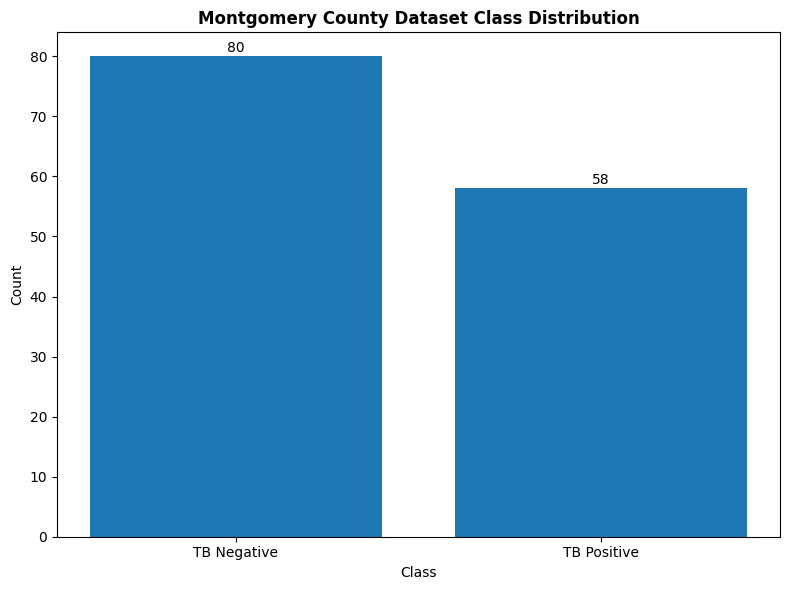

Saved to: /content/drive/MyDrive/Insight_Hunters_Project/05_Results/Figures/montgomery_class_distribution.png


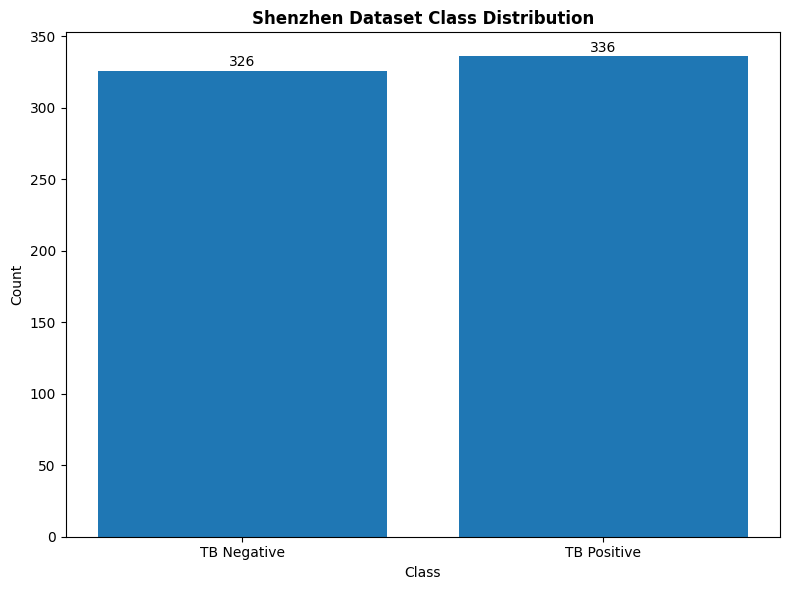

Saved to: /content/drive/MyDrive/Insight_Hunters_Project/05_Results/Figures/shenzhen_class_distribution.png

NIH DATASET
Total NIH images: 112,120

NIH CLASS DISTRIBUTION
No Finding            60361
Infiltration          19894
Effusion              13317
Atelectasis           11559
Nodule                 6331
Mass                   5782
Pneumothorax           5302
Consolidation          4667
Pleural_Thickening     3385
Cardiomegaly           2776
Emphysema              2516
Edema                  2303
Fibrosis               1686
Pneumonia              1431
Hernia                  227
dtype: int64


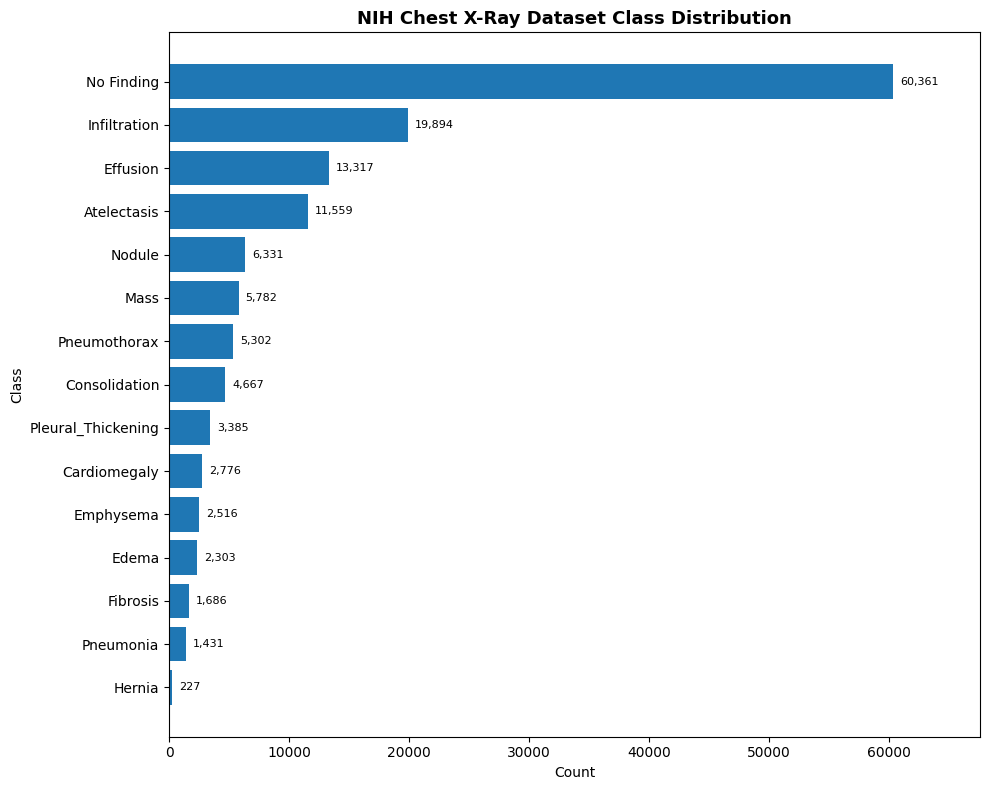

Saved to: /content/drive/MyDrive/Insight_Hunters_Project/05_Results/Figures/nih_class_distribution.png


In [ ]:

# The Montgomery graph

plot_distribution(
    montgomery_counts,
    "Montgomery County Dataset Class Distribution",
    "montgomery_class_distribution.png"
)


# The Shenzhen graph

plot_distribution(
    shenzhen_counts,
    "Shenzhen Dataset Class Distribution",
    "shenzhen_class_distribution.png"
)



# NIH Data

nih_df = pd.read_csv(NIH_METADATA)

print("\nNIH DATASET")
print("=" * 60)

print(f"Total NIH images: {len(nih_df):,}")



# NIH multi-label class distribution

nih_labels = (
    nih_df["Finding Labels"]
    .str.get_dummies(sep="|")
)

nih_counts = (
    nih_labels
    .sum()
    .sort_values(ascending=False)
)

print("\nNIH CLASS DISTRIBUTION")
print("=" * 60)
print(nih_counts)

fig, ax = plt.subplots(figsize=(10, 8))

bars = ax.barh(
    nih_counts.index,
    nih_counts.values
)

ax.set_title(
    "NIH Chest X-Ray Dataset Class Distribution",
    fontsize=13,
    fontweight="bold"
)

ax.set_xlabel("Count")
ax.set_ylabel("Class")

# Displaying the most common class at the top
ax.invert_yaxis()

# Had to add a bit more space to the black graph frame
ax.set_xlim(0, nih_counts.max() * 1.12)

# Adding the count beside each bar
for bar in bars:

    width = bar.get_width()

    ax.annotate(
        f"{int(width):,}",
        xy=(
            width,
            bar.get_y() + bar.get_height() / 2
        ),
        xytext=(5, 0),
        textcoords="offset points",
        va="center",
        fontsize=8
    )

plt.tight_layout()

save_path = RESULTS_DIR / "nih_class_distribution.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print(f"Saved to: {save_path}")


In [ ]:
# Demographic Analysis

MONTGOMERY_CLINICAL = MONTGOMERY_DIR / "ClinicalReadings"
SHENZHEN_CLINICAL = SHENZHEN_DIR / "ClinicalReadings"

# Parsing the Shenzhen clinical reading

shenzhen_demographics = []

for file_path in sorted(SHENZHEN_CLINICAL.glob("*.txt")):

    with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
        lines = f.readlines()

    if len(lines) == 0:
        continue

    # Example:
    # male 45yrs

    first_line = lines[0].strip().lower()

    gender = "Unspecified"
    age = None

    if first_line.startswith("male"):
        gender = "Male"

    elif first_line.startswith("female"):
        gender = "Female"

    # Extracting the age
    import re

    age_match = re.search(r"(\d+)\s*yrs?", first_line)

    if age_match:
        age = int(age_match.group(1))

    shenzhen_demographics.append({
        "filename": file_path.name,
        "gender": gender,
        "age": age
    })


shenzhen_demo_df = pd.DataFrame(shenzhen_demographics)

print("SHENZHEN DEMOGRAPHICS")
print("=" * 60)

print(f"Clinical records read: {len(shenzhen_demo_df)}")

print("\nGender counts:")
print(shenzhen_demo_df["gender"].value_counts())

print("\nAge summary:")
print(shenzhen_demo_df["age"].describe())

SHENZHEN DEMOGRAPHICS
Clinical records read: 662

Gender counts:
gender
Male           449
Female         210
Unspecified      3
Name: count, dtype: int64

Age summary:
count    658.000000
mean      35.582067
std       14.670406
min        1.000000
25%       26.000000
50%       33.000000
75%       43.000000
max       89.000000
Name: age, dtype: float64


In [ ]:
# Parsing the Montgomery clinical readings

montgomery_demographics = []

for file_path in sorted(MONTGOMERY_CLINICAL.glob("*.txt")):

    with open(file_path, "r", encoding="utf-8", errors="ignore") as f:
        lines = f.readlines()

    gender = "Unspecified"
    age = None

    for line in lines:

        line = line.strip()

        # Example:
        # Patient's Sex: F

        if line.lower().startswith("patient's sex"):

            value = line.split(":")[-1].strip().upper()

            if value == "M":
                gender = "Male"

            elif value == "F":
                gender = "Female"

        # Example:
        # Patient's Age: 027Y

        elif line.lower().startswith("patient's age"):

            age_match = re.search(r"(\d+)", line)

            if age_match:
                age = int(age_match.group(1))

    montgomery_demographics.append({
        "filename": file_path.name,
        "gender": gender,
        "age": age
    })


montgomery_demo_df = pd.DataFrame(montgomery_demographics)

print("\nMONTGOMERY DEMOGRAPHICS")
print("=" * 60)

print(f"Clinical records read: {len(montgomery_demo_df)}")

print("\nGender counts:")
print(montgomery_demo_df["gender"].value_counts())

print("\nAge summary:")
print(montgomery_demo_df["age"].describe())


MONTGOMERY DEMOGRAPHICS
Clinical records read: 138

Gender counts:
gender
Female         74
Male           63
Unspecified     1
Name: count, dtype: int64

Age summary:
count    138.000000
mean      40.108696
std       18.789531
min        4.000000
25%       28.000000
50%       40.000000
75%       51.750000
max       89.000000
Name: age, dtype: float64


In [ ]:
# Preparing the NIH demographics

nih_demo_df = nih_df[
    ["Patient ID", "Patient Age", "Patient Gender"]
].copy()

nih_demo_df["gender"] = (
    nih_demo_df["Patient Gender"]
    .replace({
        "M": "Male",
        "F": "Female"
    })
)

nih_demo_df["age"] = nih_demo_df["Patient Age"]


print("\nNIH DEMOGRAPHICS")
print("=" * 60)

print("\nGender counts:")
print(nih_demo_df["gender"].value_counts())

print("\nAge summary:")
print(nih_demo_df["age"].describe())


NIH DEMOGRAPHICS

Gender counts:
gender
Male      63340
Female    48780
Name: count, dtype: int64

Age summary:
count    112120.000000
mean         46.901463
std          16.839923
min           1.000000
25%          35.000000
50%          49.000000
75%          59.000000
max         414.000000
Name: age, dtype: float64


In [ ]:
# Gender distribution graphs

def plot_gender_distribution(df, dataset_name):

    counts = (
        df["gender"]
        .value_counts()
        .reindex(
            ["Male", "Female", "Unspecified"],
            fill_value=0
        )
    )

    # Removing the categories with zero observations
    counts = counts[counts > 0]

    fig, ax = plt.subplots(figsize=(7, 5))

    bars = ax.bar(
        counts.index,
        counts.values
    )

    ax.set_title(
        f"{dataset_name} Gender Distribution",
        fontsize=13,
        fontweight="bold"
    )

    ax.set_xlabel("Gender")
    ax.set_ylabel("Count")

    # Adding numbers above the bars
    for bar in bars:

        height = bar.get_height()

        ax.annotate(
            f"{int(height):,}",
            xy=(
                bar.get_x() + bar.get_width() / 2,
                height
            ),
            xytext=(0, 3),
            textcoords="offset points",
            ha="center"
        )

    # Giving the labels some space
    ax.set_ylim(
        0,
        counts.max() * 1.12
    )

    plt.tight_layout()

    filename = (
        dataset_name
        .lower()
        .replace(" ", "_")
        + "_gender_distribution.png"
    )

    save_path = RESULTS_DIR / filename

    plt.savefig(
        save_path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print(f"Saved to: {save_path}")

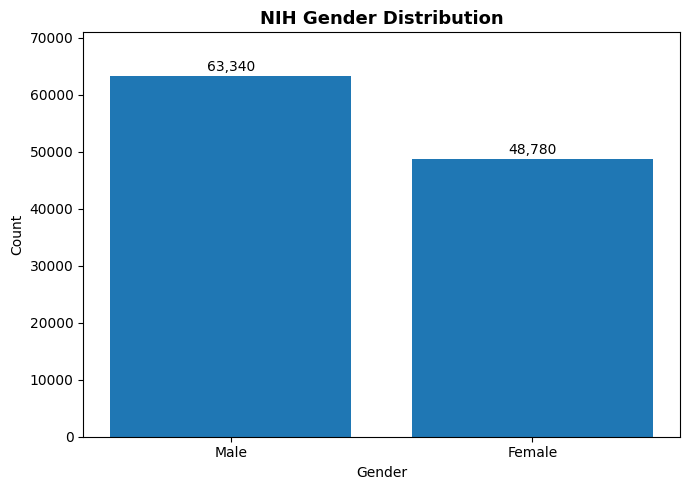

Saved to: /content/drive/MyDrive/Insight_Hunters_Project/05_Results/Figures/nih_gender_distribution.png


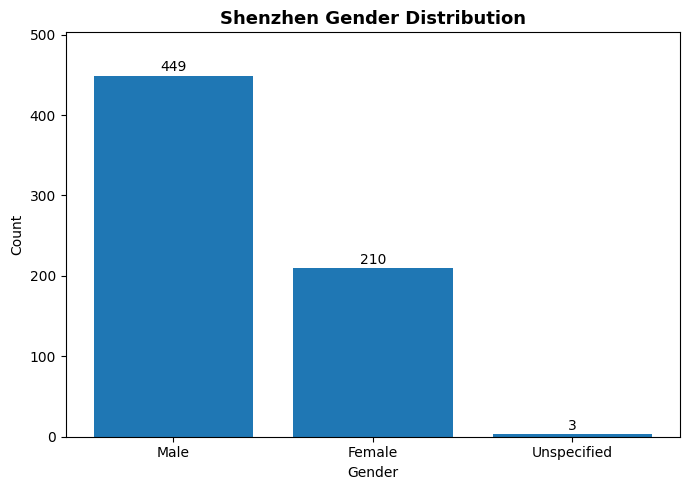

Saved to: /content/drive/MyDrive/Insight_Hunters_Project/05_Results/Figures/shenzhen_gender_distribution.png


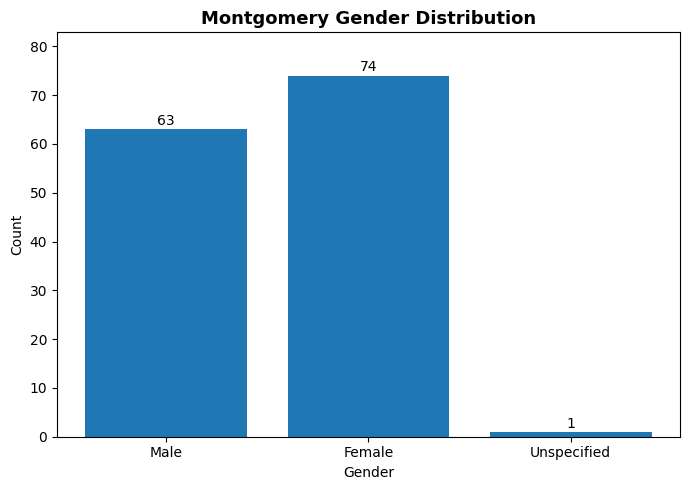

Saved to: /content/drive/MyDrive/Insight_Hunters_Project/05_Results/Figures/montgomery_gender_distribution.png


In [ ]:
plot_gender_distribution(
    nih_demo_df,
    "NIH"
)

plot_gender_distribution(
    shenzhen_demo_df,
    "Shenzhen"
)

plot_gender_distribution(
    montgomery_demo_df,
    "Montgomery"
)

In [ ]:

# Image format and dimension analysis

from PIL import Image
from collections import Counter


def analyse_image_properties(image_paths, dataset_name):

    dimension_counts = Counter()
    format_counts = Counter()
    mode_counts = Counter()

    unreadable = []

    print(f"\nANALYSING {dataset_name.upper()} IMAGE PROPERTIES")
    print("=" * 60)

    for i, image_path in enumerate(image_paths, start=1):

        try:
            with Image.open(image_path) as img:

                dimension_counts[img.size] += 1
                format_counts[img.format] += 1
                mode_counts[img.mode] += 1

        except Exception as e:

            unreadable.append(
                (str(image_path), str(e))
            )

        # Progress message for large datasets
        if i % 10000 == 0:
            print(
                f"Processed {i:,} images..."
            )

    print(f"\nTotal images checked: {len(image_paths):,}")

    print("\nFile formats:")
    for image_format, count in format_counts.items():
        print(
            f"{image_format}: {count:,}"
        )

    print("\nImage dimensions:")
    for dimensions, count in dimension_counts.most_common():

        width, height = dimensions

        print(
            f"{width} x {height}: {count:,}"
        )

    print("\nImage modes:")
    for mode, count in mode_counts.items():
        print(
            f"{mode}: {count:,}"
        )

    print(
        f"\nUnreadable images: {len(unreadable)}"
    )

    return {
        "dimensions": dimension_counts,
        "formats": format_counts,
        "modes": mode_counts,
        "unreadable": unreadable
    }

In [ ]:

# Finding all the NIH images

nih_image_files = sorted(
    NIH_DIR.rglob("*.png")
)

print("NIH IMAGE SEARCH")
print("=" * 60)

print(
    f"NIH PNG images found: "
    f"{len(nih_image_files):,}"
)

if len(nih_image_files) != 112120:

    print(
        "\nWARNING:"
        "\nExpected 112,120 NIH images."
        f"\nFound {len(nih_image_files):,}."
        "\nCheck the NIH folders before continuing."
    )

else:

    print(
        "\nAll 112,120 NIH images were found successfully."
    )

NIH IMAGE SEARCH
NIH PNG images found: 112,120

All 112,120 NIH images were found successfully.


In [ ]:
# Montgomery Image properties

montgomery_properties = analyse_image_properties(
    montgomery_files,
    "Montgomery"
)


ANALYSING MONTGOMERY IMAGE PROPERTIES

Total images checked: 138

File formats:
PNG: 138

Image dimensions:
4020 x 4892: 97
4892 x 4020: 41

Image modes:
L: 138

Unreadable images: 0


In [ ]:
# Shenzhen Image properties

shenzhen_properties = analyse_image_properties(
    shenzhen_files,
    "Shenzhen"
)


ANALYSING SHENZHEN IMAGE PROPERTIES

Total images checked: 662

File formats:
PNG: 662

Image dimensions:
3000 x 2939: 15
3000 x 2945: 15
3000 x 2947: 12
3000 x 2951: 11
3000 x 2937: 11
3000 x 2943: 11
3000 x 2949: 11
3000 x 2941: 10
3000 x 2933: 7
3000 x 2931: 6
3000 x 2935: 5
2991 x 2992: 4
3000 x 2953: 4
3000 x 2927: 3
3000 x 2955: 3
3000 x 2967: 3
2991 x 2993: 3
2997 x 2943: 3
3000 x 2925: 3
3000 x 2919: 2
3000 x 2959: 2
2996 x 2941: 2
3000 x 3001: 2
2997 x 2933: 2
2992 x 2989: 2
2990 x 2993: 2
2986 x 2992: 2
2991 x 2995: 2
2992 x 2994: 2
3001 x 3001: 2
2996 x 2989: 2
3000 x 2965: 2
2995 x 2986: 2
3001 x 2988: 2
3001 x 2989: 2
2987 x 2945: 1
2775 x 2948: 1
2306 x 2320: 1
2516 x 2942: 1
3000 x 2921: 1
2789 x 2908: 1
2991 x 2907: 1
2760 x 2555: 1
2868 x 2953: 1
2997 x 2925: 1
2357 x 2461: 1
2989 x 2939: 1
3000 x 2957: 1
2395 x 2600: 1
3000 x 2963: 1
2744 x 3000: 1
2844 x 3001: 1
2498 x 2481: 1
2308 x 2308: 1
2699 x 2927: 1
2996 x 2931: 1
2985 x 2935: 1
2419 x 2548: 1
2531 x 2890: 1


In [ ]:
# NIH Image property analysis

from PIL import Image
from collections import Counter
import time


print("=" * 70)
print("NIH IMAGE PROPERTY ANALYSIS")
print("=" * 70)

print(f"Total NIH images to analyse: {len(nih_image_files):,}")
print("Analysis mode: FULL DATASET")
print("Progress updates: every 500 images")
print()

# Storage for the results

dimension_counts = Counter()
format_counts = Counter()
mode_counts = Counter()

unreadable = []

total_images = len(nih_image_files)

start_time = time.time()


# Analysing every image

for i, image_path in enumerate(nih_image_files, start=1):

    try:

        with Image.open(image_path) as img:

            # Image dimensions
            dimension_counts[img.size] += 1

            # File format
            format_counts[img.format] += 1

            # Pillow image mode
            mode_counts[img.mode] += 1


    except Exception as e:

        unreadable.append({
            "file": str(image_path),
            "error": str(e)
        })


    # Progress update (An analysis on 120 thousand images with no update can be annoying to navigate)

    if i % 500 == 0 or i == total_images:

        elapsed_seconds = time.time() - start_time

        elapsed_minutes = elapsed_seconds / 60

        images_per_second = (
            i / elapsed_seconds
            if elapsed_seconds > 0
            else 0
        )

        percentage = (
            i / total_images
        ) * 100


        # Estimating the remaining time based on average speed so far

        remaining_images = total_images - i

        if images_per_second > 0:

            remaining_seconds = (
                remaining_images
                / images_per_second
            )

            remaining_minutes = (
                remaining_seconds / 60
            )

        else:

            remaining_minutes = 0


        print(
            f"Processed {i:,} / {total_images:,} "
            f"({percentage:.2f}%)"
        )

        print(
            f"Elapsed: {elapsed_minutes:.1f} min | "
            f"Speed: {images_per_second:.2f} images/sec | "
            f"Estimated remaining: {remaining_minutes:.1f} min"
        )

        print("-" * 70)


# Saving the results

nih_properties = {

    "dimensions": dimension_counts,

    "formats": format_counts,

    "modes": mode_counts,

    "unreadable": unreadable
}


# Final results

total_time = time.time() - start_time


print("\n" + "=" * 70)
print("NIH FULL IMAGE ANALYSIS COMPLETE")
print("=" * 70)


print(
    f"\nImages analysed: "
    f"{total_images:,}"
)


print(
    f"Total processing time: "
    f"{total_time / 60:.2f} minutes"
)


# File formats

print("\nFILE FORMATS")
print("-" * 70)

for image_format, count in format_counts.most_common():

    percentage = (
        count / total_images
    ) * 100

    print(
        f"{image_format}: "
        f"{count:,} "
        f"({percentage:.2f}%)"
    )


# Image dimensions

print("\nIMAGE DIMENSIONS")
print("-" * 70)

for dimensions, count in dimension_counts.most_common():

    width, height = dimensions

    percentage = (
        count / total_images
    ) * 100

    print(
        f"{width} x {height}: "
        f"{count:,} "
        f"({percentage:.2f}%)"
    )


# Image modes

print("\nIMAGE MODES")
print("-" * 70)

for mode, count in mode_counts.most_common():

    percentage = (
        count / total_images
    ) * 100

    print(
        f"{mode}: "
        f"{count:,} "
        f"({percentage:.2f}%)"
    )


# Unreadable images

print("\nUNREADABLE IMAGES")
print("-" * 70)

print(
    f"Unreadable images: "
    f"{len(unreadable):,}"
)


if unreadable:

    print(
        "\nUnreadable files:"
    )

    for item in unreadable:

        print(
            f"{item['file']} "
            f"-> {item['error']}"
        )


# Final verification

successfully_read = (
    total_images
    - len(unreadable)
)


print("\n" + "=" * 70)
print("FINAL VERIFICATION")
print("=" * 70)

print(
    f"Images discovered:       "
    f"{total_images:,}"
)

print(
    f"Successfully inspected:  "
    f"{successfully_read:,}"
)

print(
    f"Unreadable:              "
    f"{len(unreadable):,}"
)


if (
    total_images == 112120
    and len(unreadable) == 0
):

    print(
        "\nALL 112,120 NIH IMAGES "
        "WERE SUCCESSFULLY INSPECTED."
    )

elif total_images != 112120:

    print(
        "\nWARNING: The number of NIH images "
        "does not equal the expected 112,120."
    )

else:

    print(
        "\nWARNING: One or more NIH images "
        "could not be inspected."
    )

NIH IMAGE PROPERTY ANALYSIS
Total NIH images to analyse: 112,120
Analysis mode: FULL DATASET
Progress updates: every 500 images

Processed 500 / 112,120 (0.45%)
Elapsed: 2.2 min | Speed: 3.76 images/sec | Estimated remaining: 495.1 min
----------------------------------------------------------------------
Processed 1,000 / 112,120 (0.89%)
Elapsed: 4.5 min | Speed: 3.72 images/sec | Estimated remaining: 498.1 min
----------------------------------------------------------------------
Processed 1,500 / 112,120 (1.34%)
Elapsed: 6.8 min | Speed: 3.67 images/sec | Estimated remaining: 502.6 min
----------------------------------------------------------------------
Processed 2,000 / 112,120 (1.78%)
Elapsed: 9.1 min | Speed: 3.64 images/sec | Estimated remaining: 503.8 min
----------------------------------------------------------------------
Processed 2,500 / 112,120 (2.23%)
Elapsed: 11.4 min | Speed: 3.65 images/sec | Estimated remaining: 500.9 min
-------------------------------------------

In [ ]:
import pandas as pd
from collections import Counter
from pathlib import Path

# Restoring the NIH full scan results

nih_properties = {
    "dimensions": Counter({
        (1024, 1024): 112120
    }),

    "formats": Counter({
        "PNG": 112120
    }),

    "modes": Counter({
        "L": 111601,
        "RGBA": 519
    }),

    "unreadable": []
}


# Verifying the restored NIH results

assert sum(nih_properties["dimensions"].values()) == 112120
assert sum(nih_properties["formats"].values()) == 112120
assert sum(nih_properties["modes"].values()) == 112120
assert len(nih_properties["unreadable"]) == 0


print("=" * 70)
print("VERIFIED NIH FULL-SCAN RESULTS RESTORED")
print("=" * 70)

print("Images inspected: 112,120")
print("Format: PNG = 112,120 (100.00%)")
print("Dimensions: 1024 x 1024 = 112,120 (100.00%)")
print("Image modes: L = 111,601 (99.54%) | RGBA = 519 (0.46%)")
print("Unreadable images: 0")
print("Original full-scan processing time: 524.02 minutes")
print("\n✓ NIH results restored without rescanning images.")

VERIFIED NIH FULL-SCAN RESULTS RESTORED
Images inspected: 112,120
Format: PNG = 112,120 (100.00%)
Dimensions: 1024 x 1024 = 112,120 (100.00%)
Image modes: L = 111,601 (99.54%) | RGBA = 519 (0.46%)
Unreadable images: 0
Original full-scan processing time: 524.02 minutes

✓ NIH results restored without rescanning images.


In [ ]:
# Checking the required variables

required_variables = [
    "shenzhen_properties",
    "montgomery_properties",
    "shenzhen_files",
    "montgomery_files",
    "nih_counts",
    "shenzhen_counts",
    "montgomery_counts",
    "PROJECT_ROOT"
]

missing_variables = [
    variable
    for variable in required_variables
    if variable not in globals()
]


if missing_variables:

    print("\n" + "=" * 70)
    print("STOP: REQUIRED VARIABLES ARE MISSING")
    print("=" * 70)

    print(
        "\nThe Colab runtime has also forgotten these variables:"
    )

    for variable in missing_variables:
        print(f"  ✗ {variable}")

    print(
        "\nRerun the earlier setup/analysis cells that create ONLY "
        "the variables listed above."
    )

    print(
        "\nDO NOT rerun the full NIH image-property scan."
    )

    raise RuntimeError(
        "Required variables are missing. "
        "Restore them before running the final summary."
    )


print("\n✓ All other required variables are available.")



✓ All other required variables are available.


In [ ]:
# The helper functions

def format_dimensions(properties):

    return "; ".join(
        f"{width}x{height} ({count:,})"
        for (width, height), count
        in properties["dimensions"].most_common()
    )


def format_formats(properties):

    return ", ".join(
        f"{fmt} ({count:,})"
        for fmt, count
        in properties["formats"].most_common()
    )


def format_modes(properties):

    return ", ".join(
        f"{mode} ({count:,})"
        for mode, count
        in properties["modes"].most_common()
    )


In [ ]:
# NIH image count
# We are basically using the confirmed full-scan count rather than requiring
# nih_image_files to still exist after the runtime reset.

NIH_TOTAL_IMAGES = 112120

In [ ]:
# Image property summary

image_property_summary = pd.DataFrame({

    "Dataset": [
        "NIH",
        "Shenzhen",
        "Montgomery"
    ],

    "Images Checked": [
        NIH_TOTAL_IMAGES,
        len(shenzhen_files),
        len(montgomery_files)
    ],

    "Format": [
        format_formats(nih_properties),
        format_formats(shenzhen_properties),
        format_formats(montgomery_properties)
    ],

    "Dimensions": [
        format_dimensions(nih_properties),
        format_dimensions(shenzhen_properties),
        format_dimensions(montgomery_properties)
    ],

    "Image Mode": [
        format_modes(nih_properties),
        format_modes(shenzhen_properties),
        format_modes(montgomery_properties)
    ],

    "Unreadable": [
        len(nih_properties["unreadable"]),
        len(shenzhen_properties["unreadable"]),
        len(montgomery_properties["unreadable"])
    ]
})


print("\n" + "=" * 70)
print("IMAGE PROPERTY SUMMARY")
print("=" * 70)

display(image_property_summary)


# Creating a results directory

RESULTS_DIR = (
    Path(PROJECT_ROOT)
    / "05_Results"
)

RESULTS_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# Saving the image property summary

image_summary_path = (
    RESULTS_DIR
    / "image_property_summary.csv"
)

image_property_summary.to_csv(
    image_summary_path,
    index=False
)

print(
    f"\n✓ Image property summary saved to:\n"
    f"{image_summary_path}"
)



IMAGE PROPERTY SUMMARY


,Dataset,Images Checked,Format,Dimensions,Image Mode,Unreadable
0,NIH,112120,"PNG (112,120)","1024x1024 (112,120)","L (111,601), RGBA (519)",0
1,Shenzhen,662,PNG (662),3000x2939 (15); 3000x2945 (15); 3000x2947 (12)...,"P (635), RGB (27)",0
2,Montgomery,138,PNG (138),4020x4892 (97); 4892x4020 (41),L (138),0



✓ Image property summary saved to:
/content/drive/MyDrive/Insight_Hunters_Project/05_Results/image_property_summary.csv


In [ ]:
# Extracting the verified class counts

shenzhen_negative = int(
    shenzhen_counts["TB Negative"]
)

shenzhen_positive = int(
    shenzhen_counts["TB Positive"]
)

montgomery_negative = int(
    montgomery_counts["TB Negative"]
)

montgomery_positive = int(
    montgomery_counts["TB Positive"]
)


# Creating the final dataset summary

dataset_summary = pd.DataFrame({

    "Dataset": [
        "NIH Chest X-Ray",
        "Shenzhen",
        "Montgomery"
    ],

    "Total Images": [
        NIH_TOTAL_IMAGES,
        len(shenzhen_files),
        len(montgomery_files)
    ],

    "Classification Type": [
        "Multi-label",
        "Binary",
        "Binary"
    ],

    "Classes": [
        len(nih_counts),
        2,
        2
    ],

    "TB Negative": [
        "N/A",
        shenzhen_negative,
        montgomery_negative
    ],

    "TB Positive": [
        "N/A",
        shenzhen_positive,
        montgomery_positive
    ],

    "Unreadable Images": [
        len(nih_properties["unreadable"]),
        len(shenzhen_properties["unreadable"]),
        len(montgomery_properties["unreadable"])
    ]
})


print("\n" + "=" * 70)
print("FINAL DATASET STRUCTURE AND STATISTICS SUMMARY")
print("=" * 70)

display(dataset_summary)


# Saving the final dataset summary

dataset_summary_path = (
    RESULTS_DIR
    / "dataset_structure_summary.csv"
)

dataset_summary.to_csv(
    dataset_summary_path,
    index=False
)

print(
    f"\n✓ Final dataset summary saved to:\n"
    f"{dataset_summary_path}"
)



FINAL DATASET STRUCTURE AND STATISTICS SUMMARY


,Dataset,Total Images,Classification Type,Classes,TB Negative,TB Positive,Unreadable Images
0,NIH Chest X-Ray,112120,Multi-label,15,N/A,N/A,0
1,Shenzhen,662,Binary,2,326,336,0
2,Montgomery,138,Binary,2,80,58,0



✓ Final dataset summary saved to:
/content/drive/MyDrive/Insight_Hunters_Project/05_Results/dataset_structure_summary.csv


In [ ]:
# Calculating the overall totals

combined_tb_images = (
    len(shenzhen_files)
    + len(montgomery_files)
)

combined_tb_negative = (
    shenzhen_negative
    + montgomery_negative
)

combined_tb_positive = (
    shenzhen_positive
    + montgomery_positive
)

total_images_all_datasets = (
    NIH_TOTAL_IMAGES
    + len(shenzhen_files)
    + len(montgomery_files)
)

total_unreadable = (
    len(nih_properties["unreadable"])
    + len(shenzhen_properties["unreadable"])
    + len(montgomery_properties["unreadable"])
)


# Consistency checks

print("\n" + "=" * 70)
print("CONSISTENCY CHECKS")
print("=" * 70)


assert NIH_TOTAL_IMAGES == 112120, (
    "NIH image count should equal 112,120."
)

assert len(shenzhen_files) == 662, (
    "Shenzhen image count should equal 662."
)

assert len(montgomery_files) == 138, (
    "Montgomery image count should equal 138."
)

assert (
    shenzhen_negative
    + shenzhen_positive
    == len(shenzhen_files)
), (
    "Shenzhen class counts do not match "
    "the Shenzhen image count."
)

assert (
    montgomery_negative
    + montgomery_positive
    == len(montgomery_files)
), (
    "Montgomery class counts do not match "
    "the Montgomery image count."
)

assert combined_tb_images == 800, (
    "Combined binary TB dataset should contain 800 images."
)

assert combined_tb_negative == 406, (
    "Combined TB-negative count should equal 406."
)

assert combined_tb_positive == 394, (
    "Combined TB-positive count should equal 394."
)

assert (
    sum(nih_properties["formats"].values())
    == NIH_TOTAL_IMAGES
), (
    "NIH format counts do not total 112,120."
)

assert (
    sum(nih_properties["dimensions"].values())
    == NIH_TOTAL_IMAGES
), (
    "NIH dimension counts do not total 112,120."
)

assert (
    sum(nih_properties["modes"].values())
    == NIH_TOTAL_IMAGES
), (
    "NIH image-mode counts do not total 112,120."
)


print("✓ NIH full-scan totals verified")
print("✓ Shenzhen image count verified")
print("✓ Montgomery image count verified")
print("✓ Shenzhen class totals verified")
print("✓ Montgomery class totals verified")
print("✓ Combined TB dataset totals verified")
print("✓ NIH format totals verified")
print("✓ NIH dimension totals verified")
print("✓ NIH image-mode totals verified")



CONSISTENCY CHECKS
✓ NIH full-scan totals verified
✓ Shenzhen image count verified
✓ Montgomery image count verified
✓ Shenzhen class totals verified
✓ Montgomery class totals verified
✓ Combined TB dataset totals verified
✓ NIH format totals verified
✓ NIH dimension totals verified
✓ NIH image-mode totals verified


In [ ]:
# Final report

print("\n" + "=" * 70)
print(
    "DATASET STRUCTURE & STATISTICS "
    "ANALYSIS COMPLETED SUCCESSFULLY"
)
print("=" * 70)


print(f"""
Datasets analysed: 3


NIH CHEST X-RAY
---------------
Images: {NIH_TOTAL_IMAGES:,}
Classification: Multi-label
Classes: {len(nih_counts)}
Format: PNG
Dimensions: 1024 x 1024
L mode: 111,601
RGBA mode: 519
Unreadable images: 0


SHENZHEN
--------
Images: {len(shenzhen_files):,}
Classification: Binary
TB Negative: {shenzhen_negative:,}
TB Positive: {shenzhen_positive:,}
Unreadable images: {len(shenzhen_properties["unreadable"]):,}


MONTGOMERY
----------
Images: {len(montgomery_files):,}
Classification: Binary
TB Negative: {montgomery_negative:,}
TB Positive: {montgomery_positive:,}
Unreadable images: {len(montgomery_properties["unreadable"]):,}


COMBINED BINARY TB DATASET
--------------------------
Images: {combined_tb_images:,}
TB Negative: {combined_tb_negative:,}
TB Positive: {combined_tb_positive:,}


ALL THREE DATASETS
------------------
Total images: {total_images_all_datasets:,}
Total unreadable images: {total_unreadable:,}
""")


print("=" * 70)
print("ALL DATASET STRUCTURE & STATISTICS CHECKS PASSED")
print("=" * 70)


print(
    f"\nSaved outputs:\n"
    f"1. {image_summary_path}\n"
    f"2. {dataset_summary_path}"
)


DATASET STRUCTURE & STATISTICS ANALYSIS COMPLETED SUCCESSFULLY

Datasets analysed: 3


NIH CHEST X-RAY
---------------
Images: 112,120
Classification: Multi-label
Classes: 15
Format: PNG
Dimensions: 1024 x 1024
L mode: 111,601
RGBA mode: 519
Unreadable images: 0


SHENZHEN
--------
Images: 662
Classification: Binary
TB Negative: 326
TB Positive: 336
Unreadable images: 0


MONTGOMERY
----------
Images: 138
Classification: Binary
TB Negative: 80
TB Positive: 58
Unreadable images: 0


COMBINED BINARY TB DATASET
--------------------------
Images: 800
TB Negative: 406
TB Positive: 394


ALL THREE DATASETS
------------------
Total images: 112,920
Total unreadable images: 0

ALL DATASET STRUCTURE & STATISTICS CHECKS PASSED

Saved outputs:
1. /content/drive/MyDrive/Insight_Hunters_Project/05_Results/image_property_summary.csv
2. /content/drive/MyDrive/Insight_Hunters_Project/05_Results/dataset_structure_summary.csv
